In [1]:
import sys
import pandas as pd

import numpy as np
import mvEEG.mvEEG as mvEEG
import mne_bids


import matplotlib.pyplot as plt
plt.rcParams["svg.fonttype"] = "none"

import seaborn as sns 
from os import path

from glob import glob
import json
import tqdm.auto as ta


%load_ext autoreload
%autoreload 2

In [2]:
ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan"
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "010": [0, 1, 2, 3],
        "011": [971],
        "017": [1588],
        "031": [1571],
    }
)
old_beh_format = ["001", "002"]
isub_makeup_error_trials = {"001": 2}  # after exclusion, the last n trials which need to be recovered, for now

COND_COUNT_MIN = 60  # minimum number of trials per condition to include subject

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

# Checking Performance on main tasks (WM & Spatial Attention)

In [3]:
# TODO: get trial counts to figure out which participants to exclude from all analyses
# TODO: deal with sub 0s last 2 trials which did not save properly
# TODO: deal with first 2 subs having different column names

In [4]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    filey = wrangl.bids_path.copy().update(
        subject=wrangl.subs[isub], datatype="beh", suffix="beh", description=None, extension=".tsv"
    )
    beh = pd.read_csv(filey.fpath, sep="\t", index_col=0)
    beh = beh.loc[(beh.REJ != True)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    # NOTE on above - redos have REJ column but Nan values for keeps
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing
    if wrangl.subs[isub] in old_beh_format:
        beh["block_condition"] = beh["Block Condition"]

    return beh


# helper functions to compute K and accuracy by set size for the WM task
def compute_k(accs, changes, ss):
    HR = np.sum(accs * changes) / np.sum(changes)
    FA = np.sum((~accs) * (~changes)) / np.sum(~changes)
    return ss * (HR - FA)


def get_k_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    k_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        changes = np.array([c == "True" for c in curr_beh["change"].astype(str).values])
        k_by_ss[int(ss)] = compute_k(accs, changes, int(ss))
    return k_by_ss


def get_WM_acc_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


# helper functions to compute attention probe accuracies and false alarms
def compute_probe_misses(resps):
    n_misses = np.sum(resps == "space")
    n_total = len(resps)
    return n_misses / n_total


def get_probe_misses_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    miss_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        try:
            resps = curr_beh.RESP.values
            miss_by_ss[int(ss)] = compute_probe_misses(resps)
        except Exception as e:
            miss_by_ss[int(ss)] = np.nan
    return miss_by_ss


def get_probe_accs_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    try:
        beh_attn = beh_attn.query(
            "RESP != 'space'"
        )  # keep only trials where subject made a response (i.e., didn't miss)
    except Exception as e:
        print(f"Error querying RESP != 'space': {e}")
        print("will compute accuracy including all trials")

    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get accuracy info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


def get_probe_FAs_by_ss(beh_attn):
    beh_attn = beh_attn[beh_attn.relevant_num.isna()].copy()  # keep only trials where no probe number was presented
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    fa_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get false alarm info as boolean vectors
        fas = curr_beh.ACC.astype(float).astype(bool).values
        fa_by_ss[int(ss)] = 1 - np.mean(fas)  # FA rate is 1 - accuracy when no probe is presented
    return fa_by_ss

In [5]:
WM_accs = {}
WM_ks = {}
Attn_probe_accs = {}  # given a probe digit appears and was responded to, was it correctly identified as odd/even
Attn_probe_misses = {}  # given a probe appears, was it missed (i.e., identified as absent when present)
Attn_noProbe_FAs = {}  # given no probe appears, was it incorrectly identified as present
rejected_subs = []

for isub in ta.tqdm(range(wrangl.nsub)):

    # Load the data
    Xdata, ydata = wrangl.load_eeg(isub, reject=True)

    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"
    if wrangl.subs[isub] in isub_makeup_error_trials:
        beh = beh.iloc[: -isub_makeup_error_trials[wrangl.subs[isub]], :].reset_index(
            drop=True
        )  # drop last n trials to make up for lost trials during recording error
        Xdata = Xdata[: -isub_makeup_error_trials[wrangl.subs[isub]], :, :]
        ydata = ydata[: -isub_makeup_error_trials[wrangl.subs[isub]]]
    beh = beh.loc[beh.loc[:, "n_targets"].isin(["2", "4", "6", "8", 2, 4, 6, 8])]  # drop some broken makeup trials
    # print the number of trials without proves by condition (task, set size)
    no_probe_cond_counts = beh[beh.relevant_num.isna()].trial_condition.value_counts()
    if np.any(no_probe_cond_counts <= COND_COUNT_MIN):
        print(f"Subject {wrangl.subs[isub]} has insufficient no-probe trials in at least one condition.")
        print(no_probe_cond_counts)
        rejected_subs.append(wrangl.subs[isub])
    else:
        WM_accs[wrangl.subs[isub]] = get_WM_acc_by_ss(beh.query("block_condition=='memory'"))
        WM_ks[wrangl.subs[isub]] = get_k_by_ss(beh.query("block_condition=='memory'"))
        Attn_probe_accs[wrangl.subs[isub]] = get_probe_accs_by_ss(beh.query("block_condition=='attention'"))
        Attn_probe_misses[wrangl.subs[isub]] = get_probe_misses_by_ss(beh.query("block_condition=='attention'"))
        Attn_noProbe_FAs[wrangl.subs[isub]] = get_probe_FAs_by_ss(beh.query("block_condition=='attention'"))
# print rejected subs
print(f"Rejected subjects due to insufficient no-probe trials: {rejected_subs}")

  0%|          | 0/34 [00:00<?, ?it/s]

Error querying RESP != 'space': name 'RESP' is not defined
will compute accuracy including all trials
Subject 006 has insufficient no-probe trials in at least one condition.
trial_condition
A6P    68
A8N    65
A6N    61
A8P    59
A4P    56
A2N    55
A4N    55
M8P    55
A2P    53
M8N    46
M2N    46
M2P    43
M4P    41
M6P    40
M6N    38
M4N    36
Name: count, dtype: int64
Subject 008 has insufficient no-probe trials in at least one condition.
trial_condition
M2N    77
A8N    76
A6N    74
A4N    72
A2P    70
M4N    70
M8N    69
A8P    68
M6N    68
M2P    68
A4P    67
A6P    67
M4P    67
M6P    64
A2N    63
M8P    59
Name: count, dtype: int64
Subject 017 has insufficient no-probe trials in at least one condition.
trial_condition
M2P    59
M2N    58
M6P    55
M8P    55
M4N    51
A4P    50
M6N    49
A6P    49
M4P    47
M8N    47
A8N    46
A6N    43
A4N    42
A2P    42
A2N    41
A8P    39
Name: count, dtype: int64
Subject 018 has insufficient no-probe trials in at least one condition.
tria

In [6]:
json.dump(WM_ks, open("k_estimates.json", "w"))

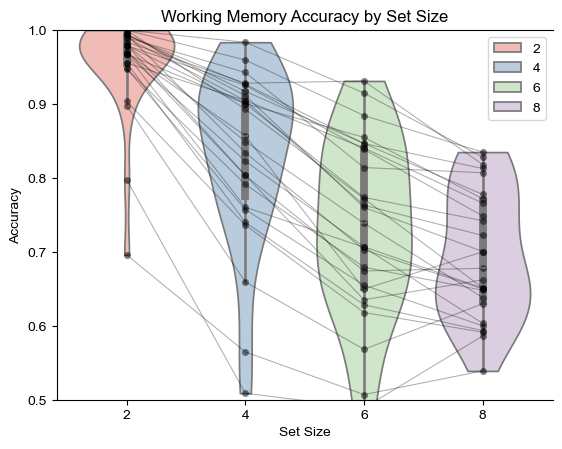

In [7]:
acc_df = (
    pd.DataFrame(WM_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=acc_df, x="Set Size", y="Accuracy", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory Accuracy by Set Size")
ax.set_ylim(0.5, 1)
sns.despine(right=True, top=False)
# plot strip plots of participants at each set size
sns.stripplot(data=acc_df, x="Set Size", y="Accuracy", color="k", alpha=0.5, jitter=False, size=5)

for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

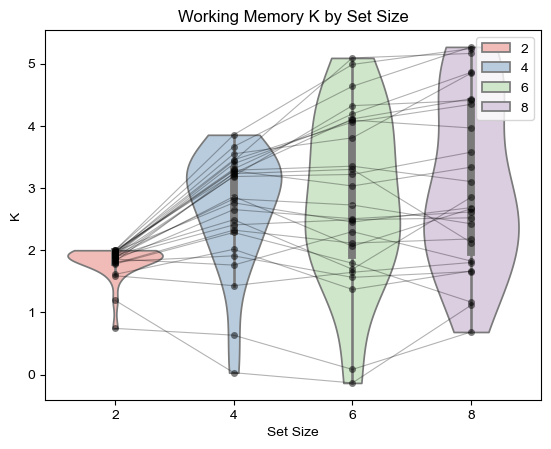

In [8]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory K by Set Size")
_ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)
# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

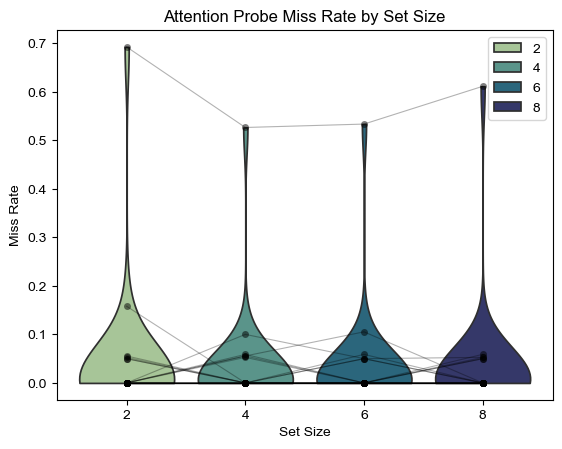

In [9]:
probe_misses_df = (
    pd.DataFrame(Attn_probe_misses)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Miss Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=probe_misses_df, x="Set Size", y="Miss Rate", cut=0, hue="Set Size", palette="crest")
plt.title("Attention Probe Miss Rate by Set Size")
_ = sns.stripplot(data=probe_misses_df, x="Set Size", y="Miss Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_misses_df.Subject.unique():
    sub_data = probe_misses_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Miss Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/Attn_probe_miss_rate_by_set_size.png", dpi=300, bbox_inches="tight", transparent=True)

In [10]:
probe_misses_df[probe_misses_df["Miss Rate"] > 0.2]

,Set Size,Subject,Miss Rate
52,2,016,0.692308
53,4,016,0.526316
54,6,016,0.533333
55,8,016,0.611111


In [11]:
probe_misses_df[probe_misses_df["Miss Rate"] > 0.2]["Miss Rate"].mean()

np.float64(0.5907669815564552)

In [12]:
probe_misses_df.query("`Miss Rate` < 0.2").groupby("Subject")["Miss Rate"].mean().describe()

count    25.000000
mean      0.012668
std       0.015961
min       0.000000
25%       0.000000
50%       0.012500
75%       0.013889
max       0.054180
Name: Miss Rate, dtype: float64

## Dropping Subject 016

In [13]:
rejected_subs.append("016")  # subject 16 has very high probe miss rate

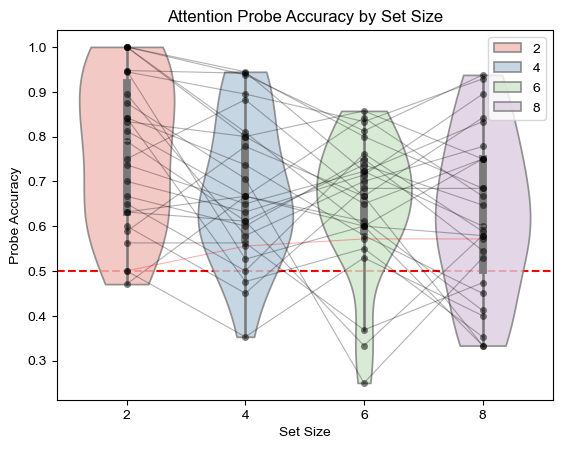

In [14]:
probe_accs_df = (
    pd.DataFrame(Attn_probe_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Probe Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_accs_df, x="Set Size", y="Probe Accuracy", cut=0, hue="Set Size", palette="Pastel1", alpha=0.8
)
plt.title("Attention Probe Accuracy by Set Size")
_ = sns.stripplot(data=probe_accs_df, x="Set Size", y="Probe Accuracy", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_accs_df.Subject.unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["Probe Accuracy"],
        color="k" if sub not in rejected_subs else "r",
        alpha=0.3,
        linewidth=0.8,
    )
_ = plt.axhline(0.5, color="r", linestyle="--", label="Chance Level", zorder=-1)

In [15]:
probe_accs_df[probe_accs_df["Set Size"] == 2]

,Set Size,Subject,Probe Accuracy
0,2,001,1.000000
4,2,002,0.562500
8,2,003,0.736842
12,2,004,0.842105
16,2,005,0.750000
20,2,007,0.631579
24,2,009,1.000000
28,2,010,0.944444
32,2,011,0.588235
36,2,012,0.500000


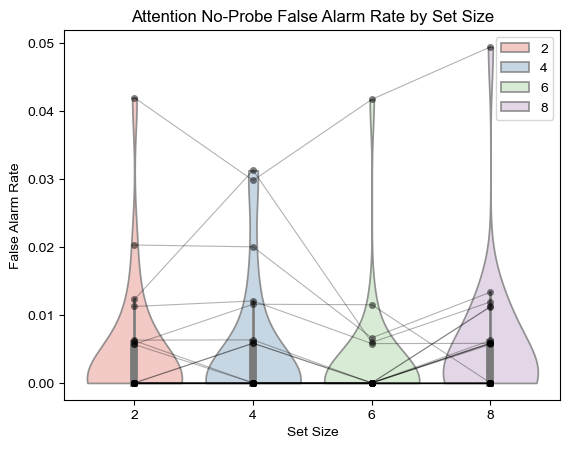

In [16]:
probe_FAs_df = (
    pd.DataFrame(Attn_noProbe_FAs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="False Alarm Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_FAs_df, x="Set Size", y="False Alarm Rate", cut=0, hue="Set Size", palette="Pastel1", alpha=0.8
)
plt.title("Attention No-Probe False Alarm Rate by Set Size")
_ = sns.stripplot(data=probe_FAs_df, x="Set Size", y="False Alarm Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_FAs_df.Subject.unique():
    sub_data = probe_FAs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3],  # hack to get the x positions of the violin/strip plots
        sub_data["False Alarm Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

In [17]:
probe_FAs_df[probe_FAs_df["False Alarm Rate"] > 0.1]

,Set Size,Subject,False Alarm Rate


In [18]:
probe_FAs_df.groupby("Subject")["False Alarm Rate"].mean().describe()

count    27.000000
mean      0.004036
std       0.008468
min       0.000000
25%       0.000000
50%       0.001412
75%       0.002862
max       0.040682
Name: False Alarm Rate, dtype: float64

# Save out final rejection list

In [19]:
import json

with open("rejected_subs.json", "w") as f:
    json.dump(rejected_subs, f)

rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

# Get the subject demographics

In [20]:
info_files = sorted(glob("../raw_data/*/*_info.csv"))
exp_info = pd.DataFrame()
for ifile in info_files:
    subid = ifile.split("/")[-2]
    sub_info = pd.read_csv(ifile)
    sub_info["subid"] = subid
    exp_info = pd.concat([exp_info, sub_info], ignore_index=True)

del exp_info["Unique ID"] # delete the Unique IDs to preserve anonymity
exp_info

,Subject,Age,Gender,subid
0,1,32,F,001
1,2,24,F,002
2,3,27,m,003
3,4,20,F,004
4,5,23,Female,005
5,6,25,Female,006
6,7,22,M,007
7,8,18,m,008
8,9,23,f,009
9,10,22,F,010


In [21]:
exp_info.Age.describe()

count    34.000000
mean     25.764706
std       4.452162
min      18.000000
25%      22.000000
50%      25.000000
75%      29.750000
max      34.000000
Name: Age, dtype: float64

In [22]:
clean_string = lambda s: s.strip().lower()[0]
exp_info["Gender_clean"] = exp_info.Gender.astype(str).apply(clean_string)
exp_info.Gender_clean.value_counts()

Gender_clean
f    18
m    15
n     1
Name: count, dtype: int64

In [23]:
rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

In [24]:
exp_info_keep = exp_info[~exp_info.subid.isin(rejected_subs)]
exp_info_keep

,Subject,Age,Gender,subid,Gender_clean
0,1,32,F,001,f
1,2,24,F,002,f
2,3,27,m,003,m
3,4,20,F,004,f
4,5,23,Female,005,f
6,7,22,M,007,m
8,9,23,f,009,f
9,10,22,F,010,f
10,11,31,f,011,f
11,12,30,f,012,f


In [25]:
exp_info_keep.Age.describe()

count    26.000000
mean     26.384615
std       4.543804
min      20.000000
25%      22.000000
50%      26.000000
75%      31.000000
max      34.000000
Name: Age, dtype: float64

In [26]:
exp_info_keep.Gender_clean.value_counts()

Gender_clean
f    15
m    10
n     1
Name: count, dtype: int64